# Análisis del Dataset Maestro: Gasto Público, Impuestos, Crecimiento Económico e Inflación en México (2015–2025)

---

### Guía rápida de lectura del cuaderno
Este cuaderno presenta, paso a paso y en lenguaje claro, cómo se comportaron el gasto del gobierno, el cobro de impuestos, la economía y los precios en México entre **enero de 2015 y marzo de 2025**:

1. **Configuración del entorno e inicialización de PySpark:** Sesión `local[*]`, monitoreo de etapas y librerías.
2. **Carga y exploración inicial del Dataset Maestro:** Revisión de la capa Gold `data/gold/dataset_maestro` (123 meses, 43 columnas) y diccionario de variables.
3. **Preparación de indicadores comparables y rezagos temporales:** Cálculo de tasas de cambio anual (`%`), rezagos (1, 3, 6 y 12 meses) y revisión del plan físico de Spark.
4. **Objetivo Específico 1 (Crecimiento económico - IGAE):** Conexión del gasto y los impuestos (total, ISR e IVA) con la actividad económica y causalidad de Granger.
5. **Objetivo Específico 2 (Inflación - INPC):** Modelo multivariado en PySpark ML, errores robustos HAC y comparativa por postura fiscal.
6. **Comparativo por periodos:** Comportamiento diferenciado en prepandemia, pandemia y pospandemia.
7. **Visualizaciones ejecutivas:** Cinco gráficas clave explicadas para presentación.
8. **Cómo trabajó Spark durante el análisis:** Métricas de jobs, tareas y etapas capturadas por `src.monitoring`.
9. **Conclusiones, recomendaciones y limitaciones.**

> **Cómo leer los números.** Cada relación se acompaña de su **valor p**: la probabilidad de ver una relación así de fuerte solo por azar. Usamos el criterio habitual de **p < 0.05** para llamarla *estadísticamente significativa*. Con 105 meses, una correlación necesita ser mayor que ±0.19 para pasar ese umbral. Todas las relaciones son **asociaciones**, no prueban por sí solas que una variable cause la otra.

---

### Planteamiento del Problema
- **Pregunta de investigación:** ¿De qué manera influye la relación entre el dinero que gasta el gobierno (Secretaría de Hacienda) y lo que cobra en impuestos (SAT) en el crecimiento económico y en la subida de precios (inflación) en México, durante el periodo de enero de 2015 a marzo de 2025?
- **Objetivo General:** Evaluar cómo afectan de forma conjunta el gasto del gobierno y la recaudación de impuestos al crecimiento de la economía y al aumento del costo de vida en México mediante PySpark.
- **Objetivos Específicos:**
  1. **Crecimiento económico (IGAE):** Identificar qué tan conectados están el gasto público y los impuestos principales (ISR e IVA) con el crecimiento económico del país, y cuánto tiempo tarda en verse su impacto.
  2. **Estabilidad de precios (INPC):** Descubrir si aumentar el cobro de impuestos ayuda a frenar la subida de precios provocada por el gasto del gobierno o si, por el contrario, la presiona al alza.

## 1. Configuración del Entorno e Inicialización de PySpark

**¿Qué hacemos en este paso?**
- Creamos la sesión con `get_spark()` de `src/ingestion/loader.py`, la misma del pipeline: una instancia `local[*]` con 12 núcleos, `spark.sql.shuffle.partitions = 4` y *event log* activado. La justificación de esa configuración se muestra en `notebooks/01_ingesta.ipynb` y en `docs/guia_optimizacion.md`.
- Cada sección etiqueta sus jobs con `etapa()`; al final (Sección 8) se resume qué hizo Spark en cada parte del análisis, con datos de la Spark UI.
- El notebook lee la **capa Gold** (`data/gold/dataset_maestro`), generada por `notebooks/01_ingesta.ipynb` o por `python -m src.pipeline`.
- Cargamos las librerías de manipulación de datos (`pyspark.sql`), estadística y aprendizaje automático (`pyspark.ml`) y visualización (`matplotlib`, `seaborn`).
- Para las pruebas de significancia (valores p, causalidad de Granger, errores robustos) usamos `scipy` y `statsmodels` sobre la tabla mensual que ya resumió Spark: son 123 filas, así que no requieren cómputo distribuido.

In [27]:
import os
import sys
from pathlib import Path

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import seaborn as sns

from pyspark.sql import Window
from pyspark.sql import functions as F
from pyspark.ml.feature import VectorAssembler
from pyspark.ml.stat import Correlation
from pyspark.ml.regression import LinearRegression

# Pruebas estadísticas sobre la serie mensual ya agregada en Spark (123 filas)
from scipy import stats
import statsmodels.api as sm
from statsmodels.tsa.stattools import adfuller, grangercausalitytests

# Configuración estética uniforme para gráficas de presentación
plt.style.use('seaborn-v0_8-whitegrid')
sns.set_palette('deep')
plt.rcParams['figure.figsize'] = (12, 5)
plt.rcParams['font.size'] = 11

# Ruta base del proyecto (funciona desde notebooks/ o desde la raíz del repo)
base_dir = Path('..').resolve() if Path('../src').exists() else Path('.').resolve()
sys.path.insert(0, str(base_dir))
from src.ingestion.loader import get_spark, GOLD_DIR
from src.monitoring import etapa, metricas

spark = get_spark('Integrador_02_Analisis')
spark.sparkContext.setLogLevel('ERROR')

print(f'Sesión de Spark activa: v{spark.version} | Spark UI: {spark.sparkContext.uiWebUrl}')
print(f'Directorio base detectado: {base_dir}')

Sesión de Spark activa: v3.5.9 | Spark UI: http://viri-rr:4040
Directorio base detectado: C:\Users\G. Viridiana\Downloads\Integrador-PGBD-26A


## 2. Carga y Exploración Inicial del Dataset Maestro

**¿Qué hacemos en este paso?**
1. **Lectura de la capa Gold:** cargamos `data/gold/dataset_maestro` (Parquet particionado por año), ordenado cronológicamente mes por mes.
2. **Revisión de cobertura:** Verificamos los **123 meses disponibles** (de enero de 2015 a marzo de 2025) y sus **43 variables**.

### Diccionario sencillo de las variables principales
| Variable | Fuente | ¿Qué mide en la vida real? |
| :--- | :--- | :--- |
| `fecha` / `anio` | Calendario | Mes de observación (`2015-01-01` a `2025-03-01`) |
| `shcp_xbc` | SHCP | Dinero total que gasta el gobierno federal cada mes (en millones de pesos) |
| `sat_total_tributarios` | SAT | Dinero total que cobra el SAT en impuestos cada mes (en millones de pesos) |
| `sat_isr` / `sat_iva` / `sat_ieps` | SAT | Cobro separado por Impuesto Sobre la Renta (ISR), IVA e IEPS |
| `igae_total` | INEGI | Termómetro mensual de la actividad económica del país (mide si la economía crece o se frena) |
| `inpc` | INEGI | Índice de precios de la canasta de bienes y servicios (sirve para calcular la inflación) |
| `ratio_tributario_gasto` | Calculada | Proporción del gasto del gobierno que se paga directamente con impuestos (`SAT / SHCP`) |

In [28]:
# Cargar la capa Gold generada por el pipeline medallion
etapa(spark, '2_carga')
ruta_maestro = str(GOLD_DIR / 'dataset_maestro')

print(f'Cargando dataset maestro desde: {ruta_maestro}')
# Sin orderBy: la ventana de la Sección 3 ya ordena por fecha (evita un shuffle extra)
df_maestro = spark.read.parquet(ruta_maestro)

print(f'Total de registros (meses): {df_maestro.count()}')
print(f'Total de variables: {len(df_maestro.columns)}')
df_maestro.printSchema()

Cargando dataset maestro desde: C:\Users\G. Viridiana\Downloads\Integrador-PGBD-26A\data\gold\dataset_maestro
Total de registros (meses): 123
Total de variables: 43
root
 |-- fecha: date (nullable = true)
 |-- shcp_xbc: double (nullable = true)
 |-- shcp_xbc10: double (nullable = true)
 |-- shcp_xbc11: double (nullable = true)
 |-- shcp_xbc1110: double (nullable = true)
 |-- shcp_xbc1111: double (nullable = true)
 |-- shcp_xbc1112: double (nullable = true)
 |-- shcp_xbc1113: double (nullable = true)
 |-- shcp_xbc1114: double (nullable = true)
 |-- shcp_xbc1120: double (nullable = true)
 |-- shcp_xbc1121: double (nullable = true)
 |-- shcp_xbc1122: double (nullable = true)
 |-- shcp_xbc1210: double (nullable = true)
 |-- shcp_xbc13: double (nullable = true)
 |-- shcp_xbc1310: double (nullable = true)
 |-- shcp_xbc1311: double (nullable = true)
 |-- shcp_xbc1312: double (nullable = true)
 |-- shcp_xbc1320: double (nullable = true)
 |-- shcp_xbc1321: double (nullable = true)
 |-- shcp_xbc

In [29]:
# Vista previa redondeada a 2 decimales para facilitar la lectura visual
cols_clave_vista = [
    'fecha', 'shcp_xbc', 'sat_total_tributarios', 'sat_isr', 'sat_iva',
    'igae_total', 'inpc', 'ratio_tributario_gasto',
    'igae_var_anual_pct', 'inflacion_anual_pct'
]

print('=== MUESTRA DE LOS PRIMEROS 5 MESES (VARIABLES CLAVE REDONDEADAS) ===')
df_vista = df_maestro.select(
    'fecha',
    *[F.round(F.col(c), 2).alias(c) for c in cols_clave_vista if c != 'fecha']
)
df_vista.orderBy('fecha').show(5, truncate=False)

# Estadísticas descriptivas redondeadas a 2 decimales
cols_resumen = [
    'shcp_xbc', 'sat_total_tributarios', 'sat_isr', 'sat_iva',
    'igae_total', 'inpc', 'ratio_tributario_gasto',
    'igae_var_anual_pct', 'inflacion_anual_pct', 'sat_real_var_anual_pct'
]

print('=== ESTADÍSTICAS DESCRIPTIVAS DE VARIABLES PRINCIPALES ===')
df_stats = df_maestro.select(cols_resumen).summary('count', 'mean', 'stddev', 'min', '50%', 'max')
df_stats.select(
    'summary',
    *[F.round(F.col(c).cast('double'), 2).alias(c) for c in cols_resumen]
).show(truncate=False)

=== MUESTRA DE LOS PRIMEROS 5 MESES (VARIABLES CLAVE REDONDEADAS) ===
+----------+---------+---------------------+---------+--------+----------+-----+----------------------+------------------+-------------------+
|fecha     |shcp_xbc |sat_total_tributarios|sat_isr  |sat_iva |igae_total|inpc |ratio_tributario_gasto|igae_var_anual_pct|inflacion_anual_pct|
+----------+---------+---------------------+---------+--------+----------+-----+----------------------+------------------+-------------------+
|2015-01-01|340847.08|241470.74            |122658.44|75966.29|90.62     |87.11|0.71                  |NULL              |NULL               |
|2015-02-01|271271.83|173802.73            |82072.11 |57558.29|89.27     |87.28|0.64                  |NULL              |NULL               |
|2015-03-01|273661.92|250012.53            |173295.55|40290.72|94.33     |87.63|0.91                  |NULL              |NULL               |
|2015-04-01|274080.37|207142.09            |117225.9 |58155.94|92.93    

In [30]:
# Validación de calidad exigida en Etapa A: granularidad, duplicados y nulos relevantes
etapa(spark, '2_validacion_calidad')

cols_criticas = ['fecha', 'shcp_xbc', 'sat_total_tributarios', 'sat_isr', 'sat_iva', 'igae_total', 'inpc']

duplicados = df_maestro.count() - df_maestro.select('fecha').distinct().count()
nulos_df = df_maestro.select([
    F.sum(F.when(F.col(c).isNull(), 1).otherwise(0)).alias(c)
    for c in cols_criticas
])

print(f"Granularidad: 1 registro por mes (123 meses únicos: 2015-01-01 a 2025-03-01)")
print(f"Duplicados en clave 'fecha': {duplicados}")
print("=== CONTEO DE NULOS EN VARIABLES CRÍTICAS ===")
nulos_df.show(truncate=False)

assert duplicados == 0, "Error: existen fechas duplicadas en la capa Gold"

Granularidad: 1 registro por mes (123 meses únicos: 2015-01-01 a 2025-03-01)
Duplicados en clave 'fecha': 0
=== CONTEO DE NULOS EN VARIABLES CRÍTICAS ===
+-----+--------+---------------------+-------+-------+----------+----+
|fecha|shcp_xbc|sat_total_tributarios|sat_isr|sat_iva|igae_total|inpc|
+-----+--------+---------------------+-------+-------+----------+----+
|0    |0       |0                    |0      |0      |0         |0   |
+-----+--------+---------------------+-------+-------+----------+----+



> **¿Qué significan estos datos?**
> - Contamos con **123 meses completos** (de enero de 2015 a marzo de 2025). Para calcular los cambios porcentuales respecto al año anterior quedan **111 meses**, ya que todo 2015 sirve como punto de partida.
> - Entre 2015 y 2025, el gobierno mexicano gastó en promedio **$424,582 millones de pesos al mes** y cobró **$291,950 millones en impuestos**.
> - Esto significa que, por cada 10 pesos que gastó el gobierno, **7 pesos salieron directamente de los impuestos** (`70.7%`) y el resto provino de otras fuentes (como ingresos petroleros, derechos o deuda).
> - En ese mismo periodo, la economía creció en promedio **1.32% al año** y los precios subieron **4.93% anual**.

### Capa de Consumo Analítico (Spark SQL) y Separación ETL vs. Consulta

* **Calculado una sola vez en el Pipeline ETL (`01_ingesta` / `src.pipeline`):** Limpieza de catálogos SHCP/SAT/INEGI, homologación de fechas mensuales, deflactación (`sat_total_real`), cálculo de ratios base (`ratio_tributario_gasto`, `ratio_isr_tributario`) y tasas anuales (`igae_var_anual_pct`, `inflacion_anual_pct`), persistidos en formato **Parquet particionado por `anio`** en `data/gold/dataset_maestro`.
* **Calculado dinámicamente en la capa de consumo:** Consultas agregadas ad-hoc sobre la vista SQL, rezagos temporales (`lag1`–`lag12`), segmentación por régimen fiscal/periodo histórico y modelos econométricos.

**Preguntas analíticas habilitadas mediante Spark SQL:**
1. **Evolución anual:** ¿Cómo ha cambiado año con año el gasto promedio, la recaudación y el porcentaje del gasto cubierto por impuestos entre 2015 y 2025?
2. **Estacionalidad y déficit mensual:** ¿En qué meses específicos se registran las mayores brechas (déficit) entre lo que gasta el gobierno y lo que recauda el SAT?
3. **Composición tributaria según inflación:** ¿Cambia la proporción de recaudación entre ISR e IVA durante los meses de alta inflación ($\ge 5\%$) frente a meses de inflación moderada ($< 5\%$)?

In [31]:
# Registrar la capa Gold como vista SQL para consumo analítico directo
etapa(spark, '2b_consumo_spark_sql')
df_maestro.createOrReplaceTempView("vw_dataset_maestro")

# Consulta 1: Evolución anual promedio de gasto, recaudación, cobertura e inflación
q1 = spark.sql("""
    SELECT 
        anio,
        COUNT(*) AS meses_registrados,
        ROUND(AVG(shcp_xbc), 1) AS gasto_mensual_prom_mdp,
        ROUND(AVG(sat_total_tributarios), 1) AS sat_mensual_prom_mdp,
        ROUND(AVG(ratio_tributario_gasto) * 100, 1) AS cobertura_tributaria_pct,
        ROUND(AVG(igae_var_anual_pct), 2) AS crecimiento_igae_pct,
        ROUND(AVG(inflacion_anual_pct), 2) AS inflacion_anual_pct
    FROM vw_dataset_maestro
    GROUP BY anio
    ORDER BY anio
""")
print("=== CONSULTA SQL 1: RESUMEN ANUAL DE FINANZAS PÚBLICAS Y MACROECONOMÍA ===")
q1.show(15, truncate=False)

# Consulta 2: Top 5 meses con mayor brecha fiscal (déficit mensual) y su inflación asociada
q2 = spark.sql("""
    SELECT 
        fecha,
        ROUND(shcp_xbc - sat_total_tributarios, 1) AS brecha_fiscal_mdp,
        ROUND(ratio_tributario_gasto * 100, 1) AS cobertura_pct,
        ROUND(inflacion_anual_pct, 2) AS inflacion_anual_pct,
        ROUND(igae_var_anual_pct, 2) AS crecimiento_igae_pct
    FROM vw_dataset_maestro
    WHERE inflacion_anual_pct IS NOT NULL
    ORDER BY brecha_fiscal_mdp DESC
    LIMIT 5
""")
print("=== CONSULTA SQL 2: MESES CON MAYOR BRECHA ENTRE GASTO Y RECAUDACIÓN ===")
q2.show(truncate=False)

# Consulta 3: Comparativa de composición tributaria (ISR vs IVA) en años de alta inflación (>5%) vs baja
q3 = spark.sql("""
    SELECT 
        CASE WHEN inflacion_anual_pct >= 5.0 THEN 'Alta Inflación (>=5%)' ELSE 'Inflación Moderada (<5%)' END AS regimen_precios,
        COUNT(*) AS meses,
        ROUND(AVG(ratio_isr_tributario) * 100, 1) AS peso_isr_pct,
        ROUND(AVG(sat_iva / sat_total_tributarios) * 100, 1) AS peso_iva_pct,
        ROUND(AVG(igae_var_anual_pct), 2) AS igae_prom_pct
    FROM vw_dataset_maestro
    WHERE inflacion_anual_pct IS NOT NULL
    GROUP BY 1
""")
print("=== CONSULTA SQL 3: ESTRUCTURA TRIBUTARIA SEGÚN RÉGIMEN INFLACIONARIO ===")
q3.show(truncate=False)

=== CONSULTA SQL 1: RESUMEN ANUAL DE FINANZAS PÚBLICAS Y MACROECONOMÍA ===
+----+-----------------+----------------------+--------------------+------------------------+--------------------+-------------------+
|anio|meses_registrados|gasto_mensual_prom_mdp|sat_mensual_prom_mdp|cobertura_tributaria_pct|crecimiento_igae_pct|inflacion_anual_pct|
+----+-----------------+----------------------+--------------------+------------------------+--------------------+-------------------+
|2015|12               |310758.5              |197205.5            |65.4                    |NULL                |NULL               |
|2016|12               |348343.5              |226351.6            |68.8                    |1.79                |2.82               |
|2017|12               |338701.4              |237460.7            |73.4                    |1.93                |6.04               |
|2018|12               |363724.0              |255194.5            |71.4                    |2.05                |4

**Interpretación de las consultas Spark SQL:**
* **Cobertura anual estable con expansión nominal (Consulta 1):** Entre 2015 y 2024 el gasto mensual promedio se duplicó (de $310.8$ a $617.7$ mil millones de pesos), pero la cobertura tributaria se mantuvo estable alrededor del **68%–73%**, con un repunte atípico al **79.0%** en el primer trimestre de 2025 por el arranque de declaraciones anuales.
* **Efecto cierre de año en el déficit (Consulta 2):** Cuatro de los cinco meses con mayor brecha fiscal ocurrieron en **diciembre** (destacando diciembre de 2024 con **$449,057$ mdp** de brecha y solo **49.4%** de cobertura tributaria), producto de la aceleración del gasto gubernamental al cierre del ejercicio fiscal.
* **Composición tributaria por entorno de precios (Consulta 3):** Durante los 42 meses de alta inflación ($\ge 5\%$), el ISR representó en promedio **56.1%** de la recaudación tributaria (3 puntos porcentuales más que en inflación moderada) y el IGAE creció **4.2%** anual, reflejando el efecto conjunto de la recuperación económica pospandemia y el ajuste de precios sobre los ingresos gravables.

## 3. Preparación de Indicadores Comparables y Rezagos Temporales en PySpark

**¿Por qué transformamos los datos antes de analizarlos?**
Si comparamos directamente montos en pesos a lo largo de 10 años, es fácil engañarnos: como los precios y el tamaño del país suben cada año, parece que todo crece junto aunque no exista una relación directa. Además, el dinero que el gobierno gasta o cobra hoy no cambia la economía de un día para otro; su efecto tarda varios meses en sentirse.

Por eso, usando funciones de ventana (`Window.orderBy('fecha')`) en PySpark creamos dos herramientas:
1. **Cambios porcentuales frente al mismo mes del año anterior (`_var_anual_pct`):** Permiten saber si el gasto, los impuestos, la economía o los precios subieron o bajaron respecto al año pasado, evitando confundirnos con meses que siempre tienen mucho movimiento (como diciembre).
2. **Valores de meses anteriores (`lag1`, `lag3`, `lag6`, `lag12`):** Nos permiten revisar si lo que el gobierno gastó o recaudó hace **1, 3, 6 o 12 meses** explica cómo se comportan la economía o los precios hoy.

In [32]:
etapa(spark, '3_indicadores')
w = Window.orderBy('fecha')

def variacion_anual(columna):
    """Calcula el cambio porcentual respecto al mismo mes del año anterior."""
    prev_12 = F.lag(columna, 12).over(w)
    return F.round(((F.col(columna) - prev_12) / prev_12) * 100, 2)

df_analitico = (
    df_maestro
    # 1. Tasas de variación anual (%)
    .withColumn('gasto_var_anual_pct', variacion_anual('shcp_xbc'))
    .withColumn('sat_var_anual_pct', variacion_anual('sat_total_tributarios'))
    # 2. Rezagos en niveles (1, 3, 6 y 12 meses)
    .withColumn('gasto_lag1', F.lag('shcp_xbc', 1).over(w))
    .withColumn('gasto_lag3', F.lag('shcp_xbc', 3).over(w))
    .withColumn('gasto_lag6', F.lag('shcp_xbc', 6).over(w))
    .withColumn('shcp_lag12', F.lag('shcp_xbc', 12).over(w))
    .withColumn('sat_lag1', F.lag('sat_total_tributarios', 1).over(w))
    .withColumn('sat_lag3', F.lag('sat_total_tributarios', 3).over(w))
    .withColumn('sat_lag6', F.lag('sat_total_tributarios', 6).over(w))
    .withColumn('sat_lag12', F.lag('sat_total_tributarios', 12).over(w))
    .withColumn('ratio_lag3', F.lag('ratio_tributario_gasto', 3).over(w))
    .withColumn('ratio_lag6', F.lag('ratio_tributario_gasto', 6).over(w))
)

# Guardamos en memoria caché para acelerar los siguientes cálculos
df_analitico.cache()
print('Variables analíticas y rezagos creados exitosamente.')

df_analitico.select(
    'fecha',
    F.round('igae_total', 2).alias('igae_total'),
    'igae_var_anual_pct',
    'inflacion_anual_pct',
    'gasto_var_anual_pct',
    'sat_var_anual_pct',
    F.round('ratio_tributario_gasto', 2).alias('ratio_tributario_gasto')
).dropna().show(5, truncate=False)

Variables analíticas y rezagos creados exitosamente.
+----------+----------+------------------+-------------------+-------------------+-----------------+----------------------+
|fecha     |igae_total|igae_var_anual_pct|inflacion_anual_pct|gasto_var_anual_pct|sat_var_anual_pct|ratio_tributario_gasto|
+----------+----------+------------------+-------------------+-------------------+-----------------+----------------------+
|2016-01-01|91.74     |1.23              |2.61               |3.11               |1.32             |0.7                   |
|2016-02-01|92.73     |3.87              |2.87               |-4.59              |12.55            |0.76                  |
|2016-03-01|94.13     |-0.22             |2.6                |-3.56              |13.15            |1.07                  |
|2016-04-01|95.75     |3.03              |2.54               |21.52              |14.74            |0.71                  |
|2016-05-01|96.0      |2.11              |2.6                |29.73            

### Cómo ejecuta Spark esta preparación

`df_analitico` se reutiliza en todas las secciones siguientes, así que se guarda en caché (`cache()`). El plan físico muestra cómo se construye la primera vez:

In [33]:
df_analitico.explain('formatted')

== Physical Plan ==
AdaptiveSparkPlan (15)
+- InMemoryTableScan (1)
      +- InMemoryRelation (2)
            +- AdaptiveSparkPlan (14)
               +- == Final Plan ==
                  * Project (9)
                  +- Window (8)
                     +- * Sort (7)
                        +- ShuffleQueryStage (6), Statistics(sizeInBytes=42.3 KiB, rowCount=123)
                           +- Exchange (5)
                              +- * ColumnarToRow (4)
                                 +- Scan parquet  (3)
               +- == Initial Plan ==
                  Project (13)
                  +- Window (12)
                     +- Sort (11)
                        +- Exchange (10)
                           +- Scan parquet  (3)


(1) InMemoryTableScan
Output [55]: [fecha#39649, shcp_xbc#39650, shcp_xbc10#39651, shcp_xbc11#39652, shcp_xbc1110#39653, shcp_xbc1111#39654, shcp_xbc1112#39655, shcp_xbc1113#39656, shcp_xbc1114#39657, shcp_xbc1120#39658, shcp_xbc1121#39659, shcp_xbc1122#396

> **Cómo leer el plan (de abajo hacia arriba):**
> 1. **`Scan parquet`** lee la capa Gold: 43 columnas repartidas en una carpeta por año (`anio=2015` … `anio=2025`). `ColumnarToRow` convierte el formato columnar de Parquet en filas para los operadores siguientes.
> 2. **`Exchange` (SinglePartition) → `Sort` → `Window`**: los `lag(12)` y rezagos usan `Window.orderBy('fecha')` sin `partitionBy`, así que Spark reúne las **123 filas en una sola partición**, las ordena y recorre la serie. Es necesario: cada mes necesita el mismo mes del año anterior.
> 3. **`AdaptiveSparkPlan`** con *Initial* y *Final Plan*: AQE ajusta el plan con las estadísticas reales del shuffle (`Statistics(sizeInBytes=42.3 KiB, rowCount=123)`).
> 4. **`InMemoryRelation` / `InMemoryTableScan`**: tras la primera acción, `df_analitico` queda en memoria, y las ~60 consultas de las secciones 4 a 7 lo leen de ahí en lugar de recalcular la ventana desde Parquet.
>
> **Optimización aplicada:** originalmente la carga hacía `spark.read.parquet(...).orderBy('fecha')`. Eso agregaba un **segundo `Exchange`** (un *range partitioning* para ordenar), redundante porque la ventana vuelve a ordenar. Al quitarlo, el análisis completo pasó de **123 a 77 jobs** y de **603 a 327 tareas**, con los mismos resultados (Sección 8).

## 4. Objetivo Específico 1: Conexión y Tiempo de Efecto en el Crecimiento Económico (IGAE)

**Pregunta guía:** *¿Qué tan conectados están el gasto público y los impuestos principales (ISR e IVA) con la actividad económica, y cuánto tiempo tarda en verse su impacto?*

Para responder con claridad y evitar falsas alarmas estadísticas, revisamos los datos en **dos pasos**:
- **Paso 4A (Comparación en montos en pesos):** Medimos qué tanto avanzan juntos los montos recaudados y gastados frente al nivel de actividad económica (`igae_total`).
- **Paso 4B (Comparación en porcentajes de crecimiento anual y meses anteriores):** Comparamos el ritmo de crecimiento (`%`) en el mismo mes y con **1, 3 y 6 meses de diferencia** (`lag1`, `lag3`, `lag6`) para ver qué ocurre primero y cuánto tarda en notarse.

In [34]:
etapa(spark, '4_objetivo1')
# Paso 4A: Correlación en niveles nominales (contemporánea y con rezagos)
cols_impuestos = [c for c in df_maestro.columns if any(k in c.lower() for k in ['isr', 'iva', 'sat_total'])]
print('Columnas tributarias disponibles:', cols_impuestos)

vars_obj1 = ['igae_total', 'shcp_xbc', 'gasto_lag1', 'gasto_lag3', 'gasto_lag6', 'shcp_lag12'] + \
            cols_impuestos + ['sat_lag1', 'sat_lag3', 'sat_lag6', 'sat_lag12']

vars_obj1 = list(dict.fromkeys([c for c in vars_obj1 if c in df_analitico.columns]))

df_corr1 = df_analitico.select(vars_obj1).dropna()
assembler1 = VectorAssembler(inputCols=vars_obj1, outputCol='features')
vec_df1 = assembler1.transform(df_corr1).select('features')

corr_matrix1 = Correlation.corr(vec_df1, 'features', 'pearson').head()[0].toArray()
df_corr_igae = pd.DataFrame(corr_matrix1, index=vars_obj1, columns=vars_obj1)

print('\n=== PASO 4A: CORRELACIÓN EN NIVELES CON EL IGAE TOTAL ===')
res_igae = df_corr_igae[['igae_total']].sort_values(by='igae_total', ascending=False)
print(res_igae.round(4))

Columnas tributarias disponibles: ['sat_total_tributarios', 'sat_isr', 'sat_iva', 'sat_total_real', 'ratio_isr_tributario']

=== PASO 4A: CORRELACIÓN EN NIVELES CON EL IGAE TOTAL ===
                       igae_total
igae_total                 1.0000
sat_iva                    0.4808
sat_total_tributarios      0.4652
gasto_lag6                 0.4577
shcp_xbc                   0.4518
sat_lag6                   0.4230
sat_lag3                   0.4035
shcp_lag12                 0.4034
gasto_lag3                 0.3966
sat_isr                    0.3837
sat_lag12                  0.3501
sat_lag1                   0.3163
sat_total_real             0.2958
gasto_lag1                 0.2638
ratio_isr_tributario       0.0192


In [35]:
etapa(spark, '4_objetivo1')
# Paso 4B: Relación en porcentajes de crecimiento anual (reutilizando la ventana w)
df_tasas = (
    df_analitico
    .select(
        'fecha', 'igae_var_anual_pct', 'gasto_var_anual_pct',
        'sat_var_anual_pct', 'inflacion_anual_pct', 'ratio_tributario_gasto'
    )
    .withColumn('gasto_var_lag1', F.lag('gasto_var_anual_pct', 1).over(w))
    .withColumn('gasto_var_lag3', F.lag('gasto_var_anual_pct', 3).over(w))
    .withColumn('gasto_var_lag6', F.lag('gasto_var_anual_pct', 6).over(w))
    .withColumn('sat_var_lag1', F.lag('sat_var_anual_pct', 1).over(w))
    .withColumn('sat_var_lag3', F.lag('sat_var_anual_pct', 3).over(w))
    .withColumn('sat_var_lag6', F.lag('sat_var_anual_pct', 6).over(w))
    .dropna()
)

# Rezago de 12 meses en tasas: se guarda aparte porque exige 6 meses más de historia (N = 99)
df_tasas12 = (
    df_analitico
    .select('fecha', 'igae_var_anual_pct', 'inflacion_anual_pct', 'gasto_var_anual_pct', 'sat_var_anual_pct', 'ratio_tributario_gasto')
    .withColumn('gasto_var_lag12', F.lag('gasto_var_anual_pct', 12).over(w))
    .withColumn('sat_var_lag12', F.lag('sat_var_anual_pct', 12).over(w))
    .dropna()
)

print(f'Observaciones válidas tras aplicar tasas anuales y rezagos de hasta 6 meses: {df_tasas.count()} meses')

cols_tasas = [c for c in df_tasas.columns if c != 'fecha']
vec_tasas = VectorAssembler(inputCols=cols_tasas, outputCol='features').transform(df_tasas)
mat_tasas = Correlation.corr(vec_tasas, 'features', 'pearson').head()[0].toArray()
pdf_corr_tasas = pd.DataFrame(mat_tasas, index=cols_tasas, columns=cols_tasas)

print('\n=== PASO 4B: RELACIÓN EN PORCENTAJES DE CRECIMIENTO ANUAL (CORTO Y MEDIANO PLAZO) ===')
print(pdf_corr_tasas[['igae_var_anual_pct', 'inflacion_anual_pct']].round(3))

Observaciones válidas tras aplicar tasas anuales y rezagos de hasta 6 meses: 105 meses

=== PASO 4B: RELACIÓN EN PORCENTAJES DE CRECIMIENTO ANUAL (CORTO Y MEDIANO PLAZO) ===
                        igae_var_anual_pct  inflacion_anual_pct
igae_var_anual_pct                   1.000                0.437
gasto_var_anual_pct                  0.148                0.054
sat_var_anual_pct                    0.327               -0.045
inflacion_anual_pct                  0.437                1.000
ratio_tributario_gasto               0.006               -0.073
gasto_var_lag1                       0.029                0.079
gasto_var_lag3                       0.106                0.048
gasto_var_lag6                       0.095                0.151
sat_var_lag1                         0.158               -0.075
sat_var_lag3                        -0.006               -0.085
sat_var_lag6                         0.172                0.052


### Paso 4C: ¿Qué relaciones son estadísticamente significativas?

Spark calcula cada correlación con `F.corr`; con ella y el número de meses obtenemos el valor p (prueba t de Pearson). Incluimos el rezago de **12 meses**, que exige un año más de historia (N = 99).

In [36]:
etapa(spark, '4_objetivo1')
def valor_p(r, n):
    # Prueba t para una correlación de Pearson con n observaciones
    t = r * np.sqrt((n - 2) / (1 - r**2))
    return 2 * stats.t.sf(abs(t), n - 2)

def tabla_significancia(df, objetivo, explicativas):
    n = df.count()
    fila = df.agg(*[F.corr(c, objetivo).alias(c) for c in explicativas]).first().asDict()
    return pd.DataFrame(
        [(c, round(r, 3), round(valor_p(r, n), 4), n) for c, r in fila.items()],
        columns=['variable', 'r', 'valor_p', 'N'],
    ).assign(significativa=lambda d: np.where(d.valor_p < 0.05, 'Sí', 'No'))

explicativas = ['gasto_var_anual_pct', 'gasto_var_lag1', 'gasto_var_lag3', 'gasto_var_lag6',
                'sat_var_anual_pct', 'sat_var_lag1', 'sat_var_lag3', 'sat_var_lag6', 'ratio_tributario_gasto']
sig_igae = pd.concat([
    tabla_significancia(df_tasas, 'igae_var_anual_pct', explicativas),
    tabla_significancia(df_tasas12, 'igae_var_anual_pct', ['gasto_var_lag12', 'sat_var_lag12']),
])
sig_inf = pd.concat([
    tabla_significancia(df_tasas, 'inflacion_anual_pct', explicativas),
    tabla_significancia(df_tasas12, 'inflacion_anual_pct', ['gasto_var_lag12', 'sat_var_lag12']),
])
print('=== CORRELACIÓN CON EL CRECIMIENTO ECONÓMICO (IGAE, var. anual %) ===')
print(sig_igae.to_string(index=False))
print('\n=== CORRELACIÓN CON LA INFLACIÓN ANUAL (INPC) ===')
print(sig_inf.to_string(index=False))

=== CORRELACIÓN CON EL CRECIMIENTO ECONÓMICO (IGAE, var. anual %) ===
              variable      r  valor_p   N significativa
   gasto_var_anual_pct  0.148   0.1307 105            No
        gasto_var_lag1  0.029   0.7663 105            No
        gasto_var_lag3  0.106   0.2828 105            No
        gasto_var_lag6  0.095   0.3365 105            No
     sat_var_anual_pct  0.327   0.0007 105            Sí
          sat_var_lag1  0.158   0.1064 105            No
          sat_var_lag3 -0.006   0.9488 105            No
          sat_var_lag6  0.172   0.0800 105            No
ratio_tributario_gasto  0.006   0.9513 105            No
       gasto_var_lag12  0.026   0.7969  99            No
         sat_var_lag12 -0.147   0.1477  99            No

=== CORRELACIÓN CON LA INFLACIÓN ANUAL (INPC) ===
              variable      r  valor_p   N significativa
   gasto_var_anual_pct  0.054   0.5831 105            No
        gasto_var_lag1  0.079   0.4202 105            No
        gasto_var_lag3  

### Paso 4C.1: Desglose por tipo de impuesto (ISR e IVA) en tasas anuales
El Objetivo Específico 1 plantea evaluar por separado el **ISR** (impuesto directo sobre ingresos y utilidades) y el **IVA** (impuesto indirecto al consumo). Calculamos sus variaciones porcentuales anuales en PySpark para verificar cuál tiene mayor vínculo con el crecimiento del IGAE.

In [37]:
etapa(spark, '4_objetivo1')
df_imp_desglose = (
    df_analitico
    .withColumn('isr_var_anual_pct', variacion_anual('sat_isr'))
    .withColumn('iva_var_anual_pct', variacion_anual('sat_iva'))
    .withColumn('isr_var_lag3', F.lag('isr_var_anual_pct', 3).over(w))
    .withColumn('iva_var_lag3', F.lag('iva_var_anual_pct', 3).over(w))
    .dropna(subset=['igae_var_anual_pct', 'isr_var_lag3', 'iva_var_lag3'])
)

cols_imp_anual = ['isr_var_anual_pct', 'isr_var_lag3', 'iva_var_anual_pct', 'iva_var_lag3']
sig_imp_igae = tabla_significancia(df_imp_desglose, 'igae_var_anual_pct', cols_imp_anual)
sig_imp_inf = tabla_significancia(df_imp_desglose, 'inflacion_anual_pct', cols_imp_anual)

print('=== CORRELACIÓN ISR E IVA (VAR. ANUAL %) CON CRECIMIENTO ECONÓMICO (IGAE) ===')
print(sig_imp_igae.to_string(index=False))
print('\n=== CORRELACIÓN ISR E IVA (VAR. ANUAL %) CON INFLACIÓN ANUAL (INPC) ===')
print(sig_imp_inf.to_string(index=False))

=== CORRELACIÓN ISR E IVA (VAR. ANUAL %) CON CRECIMIENTO ECONÓMICO (IGAE) ===
         variable      r  valor_p   N significativa
isr_var_anual_pct  0.151   0.1198 108            No
     isr_var_lag3  0.083   0.3920 108            No
iva_var_anual_pct  0.349   0.0002 108            Sí
     iva_var_lag3 -0.034   0.7288 108            No

=== CORRELACIÓN ISR E IVA (VAR. ANUAL %) CON INFLACIÓN ANUAL (INPC) ===
         variable      r  valor_p   N significativa
isr_var_anual_pct  0.274   0.0041 108            Sí
     isr_var_lag3  0.335   0.0004 108            Sí
iva_var_anual_pct -0.019   0.8433 108            No
     iva_var_lag3  0.079   0.4179 108            No


> **Lectura del desglose tributario (ISR vs. IVA):**
> - **El IVA es el termómetro inmediato del consumo:** su variación anual tiene una correlación positiva y estadísticamente significativa con el IGAE en el mismo mes (`p < 0.05`), reflejando que cuando la actividad económica crece, el consumo y el cobro de IVA reaccionan de inmediato.
> - **El ISR responde con menor sensibilidad mensual:** al depender de declaraciones provisionales y cierres fiscales anuales, su correlación contemporánea es más débil que la del IVA, confirmando que la recaudación sigue el ciclo económico.

### Paso 4D: ¿Quién se mueve primero? Prueba de causalidad de Granger

Una correlación no dice qué variable va primero. La **prueba de Granger** pregunta: *¿los valores pasados de X ayudan a predecir Y, más allá de lo que ya predicen los valores pasados de Y?* Si el valor p es menor que 0.05, decimos que **X anticipa a Y** (en sentido de Granger; sigue sin ser una prueba de causalidad económica).

La prueba exige series *estacionarias* (sin tendencia persistente). Primero lo revisamos con la prueba de Dickey-Fuller aumentada (ADF): un valor p < 0.05 indica serie estacionaria.

In [38]:
import warnings
etapa(spark, '4_objetivo1')

pdf_series = (
    df_analitico.select(
        'fecha', 'igae_var_anual_pct', 'inflacion_anual_pct',
        'gasto_var_anual_pct', 'sat_var_anual_pct', 'ratio_tributario_gasto'
    )
    .orderBy('fecha')
    .toPandas()
    .dropna()
)

with warnings.catch_warnings():
    warnings.simplefilter("ignore", FutureWarning)
    adf = pd.DataFrame(
        [(c, round(adfuller(pdf_series[c], autolag='AIC')[1], 4)) for c in pdf_series.columns if c != 'fecha'],
        columns=['serie', 'valor_p_ADF'],
    ).assign(estacionaria=lambda d: np.where(d.valor_p_ADF < 0.05, 'Sí', 'No (cautela)'))

print('=== ESTACIONARIEDAD (ADF) ===')
print(adf.to_string(index=False))

pares = [
    ('gasto_var_anual_pct', 'igae_var_anual_pct'),
    ('sat_var_anual_pct', 'igae_var_anual_pct'),
    ('igae_var_anual_pct', 'sat_var_anual_pct'),
    ('gasto_var_anual_pct', 'inflacion_anual_pct'),
    ('sat_var_anual_pct', 'inflacion_anual_pct'),
    ('ratio_tributario_gasto', 'inflacion_anual_pct'),
]

filas = []
for x, y in pares:
    res = grangercausalitytests(pdf_series[[y, x]], maxlag=6)
    ps = {f'rezago_{k}': round(res[k][0]['ssr_ftest'][1], 3) for k in res}
    filas.append({
        '¿X anticipa a Y?': f'{x} -> {y}',
        **ps,
        'significativa (algún rezago)': 'Sí' if min(ps.values()) < 0.05 else 'No'
    })

granger = pd.DataFrame(filas)
print('\n=== CAUSALIDAD DE GRANGER (valores p por rezago, en meses) ===')
print(granger.to_string(index=False))

=== ESTACIONARIEDAD (ADF) ===
                 serie  valor_p_ADF estacionaria
    igae_var_anual_pct       0.0002           Sí
   inflacion_anual_pct       0.3719 No (cautela)
   gasto_var_anual_pct       0.1686 No (cautela)
     sat_var_anual_pct       0.0001           Sí
ratio_tributario_gasto       0.2751 No (cautela)

=== CAUSALIDAD DE GRANGER (valores p por rezago, en meses) ===
                             ¿X anticipa a Y?  rezago_1  rezago_2  rezago_3  rezago_4  rezago_5  rezago_6 significativa (algún rezago)
    gasto_var_anual_pct -> igae_var_anual_pct     0.209     0.303     0.441     0.586     0.453     0.598                           No
      sat_var_anual_pct -> igae_var_anual_pct     0.120     0.470     0.642     0.433     0.500     0.428                           No
      igae_var_anual_pct -> sat_var_anual_pct     0.001     0.004     0.008     0.009     0.026     0.044                           Sí
   gasto_var_anual_pct -> inflacion_anual_pct     0.780     0.592     0.

### Paso 4E: Robustez: gasto total (XBC) frente a gasto programable (XBC10)

El indicador principal usa `shcp_xbc`, el **gasto total** del Gobierno Federal, que incluye gasto no programable (costo financiero de la deuda y participaciones a estados). La pregunta de investigación habla de **gasto programable** (`shcp_xbc10`, ~71 % del total). Repetimos las pruebas clave con ambos para comprobar que las conclusiones no dependen de esa elección.

In [39]:
etapa(spark, '4_objetivo1')
df_prog = (
    df_maestro.select('fecha', 'shcp_xbc', 'shcp_xbc10', 'igae_var_anual_pct', 'inflacion_anual_pct')
    .withColumn('gasto_total_var', variacion_anual('shcp_xbc'))
    .withColumn('gasto_programable_var', variacion_anual('shcp_xbc10'))
)
filas = []
for serie in ['gasto_total_var', 'gasto_programable_var']:
    for k in [0, 1, 3, 6, 12]:
        sub = df_prog.withColumn('x', F.lag(serie, k).over(w) if k else F.col(serie)).dropna(subset=['x', 'igae_var_anual_pct'])
        n = sub.count()
        r_igae, r_inf = sub.agg(F.corr('x', 'igae_var_anual_pct'), F.corr('x', 'inflacion_anual_pct')).first()
        filas.append({'gasto': serie, 'rezago': k, 'N': n,
                      'r IGAE': round(r_igae, 3), 'p IGAE': round(valor_p(r_igae, n), 3),
                      'r inflación': round(r_inf, 3), 'p inflación': round(valor_p(r_inf, n), 3)})
print(pd.DataFrame(filas).to_string(index=False))

pdf_prog = df_prog.select('inflacion_anual_pct', 'igae_var_anual_pct', 'gasto_total_var', 'gasto_programable_var').toPandas().dropna()
for serie in ['gasto_total_var', 'gasto_programable_var']:
    for y in ['igae_var_anual_pct', 'inflacion_anual_pct']:
        res = grangercausalitytests(pdf_prog[[y, serie]], maxlag=6)
        print(f'Granger {serie} -> {y}:', [float(round(res[k][0]['ssr_ftest'][1], 3)) for k in res])

                gasto  rezago   N  r IGAE  p IGAE  r inflación  p inflación
      gasto_total_var       0 111   0.147   0.124        0.056        0.558
      gasto_total_var       1 110   0.030   0.759        0.070        0.469
      gasto_total_var       3 108   0.102   0.294        0.077        0.430
      gasto_total_var       6 105   0.095   0.337        0.151        0.125
      gasto_total_var      12  99   0.026   0.797        0.062        0.540
gasto_programable_var       0 111   0.098   0.307       -0.011        0.910
gasto_programable_var       1 110  -0.000   0.997        0.007        0.943
gasto_programable_var       3 108   0.102   0.295        0.038        0.700
gasto_programable_var       6 105   0.020   0.838        0.110        0.263
gasto_programable_var      12  99   0.057   0.578        0.095        0.352
Granger gasto_total_var -> igae_var_anual_pct: [0.209, 0.303, 0.441, 0.586, 0.453, 0.598]
Granger gasto_total_var -> inflacion_anual_pct: [0.78, 0.592, 0.705, 0.754

> **Resultado:** con gasto programable las conclusiones no cambian. Ninguna correlación con el IGAE es significativa, y el gasto vuelve a **anticipar la inflación a 5–6 meses** en Granger (p ≈ 0.03–0.04, frente a ≈ 0.01 con gasto total). El resto del análisis conserva el gasto total.

> **¿Qué nos dicen estos números sobre el crecimiento económico?**
> 1. **En montos en pesos (Paso 4A):** el IVA, la recaudación total y el gasto aparecen correlacionados con el IGAE (entre `0.40` y `0.48`). Esta lectura es engañosa por sí sola: todas son series que crecen con el tiempo (precios y tamaño de la economía), así que se mueven juntas aunque no exista relación directa. Por eso la lectura válida es la de tasas de crecimiento.
> 2. **En ritmo de crecimiento anual (Pasos 4B y 4C):**
>    - **La recaudación va de la mano con la economía:** su crecimiento se asocia con el del IGAE en el mismo mes (`r ≈ 0.33`, valor p < 0.01, significativa).
>    - **El gasto público no muestra una relación significativa con el crecimiento** en ningún horizonte probado (mismo mes, 1, 3, 6 ni 12 meses; todas con valor p > 0.1). Las correlaciones de `0.09` a `0.15` son demasiado débiles para distinguirlas del azar con 105 meses.
> 3. **¿Quién va primero? (Paso 4D, Granger):** el crecimiento del IGAE **anticipa** el de la recaudación (valor p < 0.05 en los rezagos de 1 a 6 meses), pero la recaudación **no** anticipa al IGAE. Es decir: **la economía mueve a los impuestos, y no al revés.** Cuando a empresas y familias les va bien, el SAT recauda más.
>
> **Respuesta al Objetivo 1:** los impuestos (ISR e IVA) están conectados con la actividad económica de forma inmediata, pero como *consecuencia* del crecimiento. Con datos mensuales de 2015 a 2025 **no encontramos evidencia** de que el gasto público impulse el IGAE en un plazo de 0 a 12 meses.

## 5. Objetivo Específico 2: Efecto Conjunto del Gasto e Impuestos sobre la Inflación (INPC)

**Pregunta guía:** *¿Aumentar el cobro de impuestos ayuda a frenar la subida de precios provocada por el gasto del gobierno o la presiona al alza?*

Para responder de manera clara y comprobable, analizamos el problema desde dos ángulos:
- **Paso 5A (Modelo estadístico en PySpark ML):** Estimamos cómo se mueve la inflación anual cuando cambian al mismo tiempo el gasto del gobierno (actual y de hace 3 meses), el cobro de impuestos (actual y de hace 3 meses), la proporción del gasto cubierta con impuestos (`ratio_tributario_gasto`) y el ritmo de la economía (`igae_var_anual_pct`).
- **Paso 5B (Comparación práctica por escenarios):** Dividimos los 105 meses analizados en dos grupos reales: los meses donde el cobro de impuestos creció más rápido que el gasto vs. los meses donde el gasto creció igual o más rápido que los impuestos.

In [40]:
etapa(spark, '5_objetivo2')
# Paso 5A: Modelo de Regresión Lineal Multivariada en PySpark ML
features_inflacion = [
    'gasto_var_anual_pct', 'gasto_var_lag3',
    'sat_var_anual_pct', 'sat_var_lag3',
    'ratio_tributario_gasto', 'igae_var_anual_pct'
]

df_ml_inf = (
    df_tasas
    .select(['inflacion_anual_pct'] + features_inflacion)
    .dropna()
)

assembler_inf = VectorAssembler(inputCols=features_inflacion, outputCol='features')
data_inf = assembler_inf.transform(df_ml_inf).select('features', F.col('inflacion_anual_pct').alias('label'))

# regParam=0 y solver 'normal' (mínimos cuadrados ordinarios): así Spark reporta errores estándar y valores p
lr = LinearRegression(featuresCol='features', labelCol='label', regParam=0.0, solver='normal')
modelo_inf = lr.fit(data_inf)

print('=== PASO 5A: MODELO ECONOMÉTRICO EN PYSPARK (OBJETIVO: INFLACIÓN ANUAL %) ===')
print(f'R² (Varianza explicada): {modelo_inf.summary.r2:.4f} ({modelo_inf.summary.r2*100:.1f}%)')
print(f'RMSE (Error cuadrático medio): {modelo_inf.summary.rootMeanSquaredError:.4f} puntos porcentuales')
print(f'Intercepto: {modelo_inf.intercept:.4f}\n')

resumen = modelo_inf.summary
coef_df = pd.DataFrame({
    'variable': features_inflacion + ['intercepto'],
    'coeficiente': list(modelo_inf.coefficients.toArray()) + [modelo_inf.intercept],
    'error_estandar': resumen.coefficientStandardErrors,
    'valor_p (Spark, OLS)': resumen.pValues,
}).round(4)
print(coef_df.to_string(index=False))

=== PASO 5A: MODELO ECONOMÉTRICO EN PYSPARK (OBJETIVO: INFLACIÓN ANUAL %) ===
R² (Varianza explicada): 0.2355 (23.5%)
RMSE (Error cuadrático medio): 1.3706 puntos porcentuales
Intercepto: 5.5315

              variable  coeficiente  error_estandar  valor_p (Spark, OLS)
   gasto_var_anual_pct      -0.0017          0.0101                0.8636
        gasto_var_lag3       0.0044          0.0097                0.6472
     sat_var_anual_pct      -0.0303          0.0152                0.0489
          sat_var_lag3      -0.0080          0.0141                0.5724
ratio_tributario_gasto      -0.4485          1.2017                0.7098
    igae_var_anual_pct       0.1319          0.0249                0.0000
            intercepto       5.5315          0.8880                0.0000


### Paso 5A.1: Robustez: errores estándar corregidos por autocorrelación

Los valores p de Spark suponen que los errores de meses distintos son independientes. En series mensuales de tasas anuales eso no se cumple: el estadístico **Durbin-Watson** (cercano a 2 si no hay autocorrelación, cercano a 0 si es fuerte) lo mide. Si hay autocorrelación, los valores p de mínimos cuadrados ordinarios salen **demasiado optimistas**, así que reestimamos con errores **HAC de Newey-West** (12 rezagos). Además añadimos una variable por periodo (pandemia y pospandemia) para separar los choques de esos años.

In [41]:
etapa(spark, '5_objetivo2')
pdf_ml = df_ml_inf.toPandas()
X = sm.add_constant(pdf_ml[features_inflacion])
y = pdf_ml['inflacion_anual_pct']
ols = sm.OLS(y, X).fit()
hac = sm.OLS(y, X).fit(cov_type='HAC', cov_kwds={'maxlags': 12})
print(f'Durbin-Watson: {sm.stats.durbin_watson(ols.resid):.3f}  (2 = sin autocorrelación)')

# Mismo modelo + efectos de periodo
pdf_per = df_tasas.select('fecha', 'inflacion_anual_pct', *features_inflacion).toPandas()
pdf_per['pandemia'] = ((pdf_per.fecha >= pd.Timestamp('2020-03-01').date()) & (pdf_per.fecha < pd.Timestamp('2022-01-01').date())).astype(float)
pdf_per['pospandemia'] = (pdf_per.fecha >= pd.Timestamp('2022-01-01').date()).astype(float)
Xp = sm.add_constant(pdf_per[features_inflacion + ['pandemia', 'pospandemia']])
hac_per = sm.OLS(pdf_per['inflacion_anual_pct'], Xp).fit(cov_type='HAC', cov_kwds={'maxlags': 12})

robustez = pd.DataFrame({
    'coef': ols.params, 'p (OLS)': ols.pvalues, 'p (HAC)': hac.pvalues,
    'coef con periodos': hac_per.params, 'p con periodos (HAC)': hac_per.pvalues,
}).round(4)
print(f'R²: {ols.rsquared:.3f} sin periodos | {hac_per.rsquared:.3f} con periodos')
print(robustez.to_string())

Durbin-Watson: 0.222  (2 = sin autocorrelación)
R²: 0.235 sin periodos | 0.409 con periodos
                          coef  p (OLS)  p (HAC)  coef con periodos  p con periodos (HAC)
const                   5.5315   0.0000   0.0000             4.9893                0.0000
gasto_var_anual_pct    -0.0017   0.8636   0.8611            -0.0078                0.3501
gasto_var_lag3          0.0044   0.6472   0.7031            -0.0033                0.6991
igae_var_anual_pct      0.1319   0.0000   0.0010             0.1262                0.0000
pandemia                   NaN      NaN      NaN             0.2264                0.6927
pospandemia                NaN      NaN      NaN             1.5411                0.0310
ratio_tributario_gasto -0.4485   0.7098   0.5091            -0.0679                0.9092
sat_var_anual_pct      -0.0303   0.0489   0.0160            -0.0454                0.0003
sat_var_lag3           -0.0080   0.5724   0.5246            -0.0168                0.1597


In [42]:
etapa(spark, '5_objetivo2')
# Paso 5B: Comparativa por Regímenes Fiscales (Consolidación vs. Expansión)
df_regimenes = (
    df_tasas
    .withColumn(
        'postura_fiscal',
        F.when(F.col('sat_var_anual_pct') > F.col('gasto_var_anual_pct'), '1. Mayor esfuerzo recaudatorio (SAT > Gasto)')
         .otherwise('2. Mayor expansión del gasto (Gasto >= SAT)')
    )
)

resumen_regimenes = (
    df_regimenes
    .groupBy('postura_fiscal')
    .agg(
        F.count('*').alias('meses_observados'),
        F.round(F.avg('inflacion_anual_pct'), 2).alias('inflacion_promedio_pct'),
        F.round(F.avg('igae_var_anual_pct'), 2).alias('crecimiento_igae_promedio_pct'),
        F.round(F.avg('ratio_tributario_gasto'), 3).alias('ratio_tributario_promedio')
    )
    .orderBy('postura_fiscal')
)

print('=== PASO 5B: DESEMPEÑO MACROECONÓMICO POR POSTURA FISCAL (N = 105 MESES) ===')
resumen_regimenes.show(truncate=False)

# ¿La diferencia de inflación entre posturas es estadísticamente significativa? (t de Welch)
pdf_reg = df_regimenes.select('postura_fiscal', 'inflacion_anual_pct').toPandas()
g1, g2 = [g.inflacion_anual_pct for _, g in pdf_reg.groupby('postura_fiscal')]
print(f'Diferencia de inflación: {g1.mean() - g2.mean():.2f} pp | valor p (Welch): {stats.ttest_ind(g1, g2, equal_var=False).pvalue:.3f}')

=== PASO 5B: DESEMPEÑO MACROECONÓMICO POR POSTURA FISCAL (N = 105 MESES) ===
+--------------------------------------------+----------------+----------------------+-----------------------------+-------------------------+
|postura_fiscal                              |meses_observados|inflacion_promedio_pct|crecimiento_igae_promedio_pct|ratio_tributario_promedio|
+--------------------------------------------+----------------+----------------------+-----------------------------+-------------------------+
|1. Mayor esfuerzo recaudatorio (SAT > Gasto)|53              |4.84                  |1.43                         |0.754                    |
|2. Mayor expansión del gasto (Gasto >= SAT) |52              |5.28                  |1.14                         |0.669                    |
+--------------------------------------------+----------------+----------------------+-----------------------------+-------------------------+

Diferencia de inflación: -0.44 pp | valor p (Welch): 0.154


> **¿Qué nos dicen estos resultados sobre la inflación?**
> 1. **El modelo en conjunto sí explica una parte de la inflación:** gasto, impuestos, cobertura fiscal y actividad económica explican cerca del **23.5 %** de sus variaciones (R² ajustada ≈ 0.19; prueba F significativa). Al añadir los periodos de pandemia y pospandemia, la parte explicada sube a **~41 %**. El resto corresponde a factores que este modelo no incluye (por ejemplo: precios internacionales, tipo de cambio o la política monetaria del Banco de México); el modelo no permite repartir ese resto entre ellos.
> 2. **La autocorrelación es fuerte** (Durbin-Watson ≈ 0.2), así que la lectura confiable es la de errores robustos (HAC):
>    - **Recaudación (`sat_var_anual_pct`):** coeficiente negativo y **significativo** (p ≈ 0.02; p < 0.001 con periodos). Cuando la recaudación crece 10 puntos más rápido, la inflación es en promedio **0.3 a 0.45 puntos menor**.
>    - **Actividad económica (`igae_var_anual_pct`):** positivo y **significativo** (p ≈ 0.001): una economía más acelerada coincide con más inflación.
>    - **Gasto (actual y a 3 meses) y cobertura fiscal (`ratio_tributario_gasto`):** **no significativos** (p > 0.3). La proporción del gasto cubierta con impuestos *no* tiene un efecto distinguible del azar una vez que se controla por lo demás.
> 3. **Granger (Paso 4D):** el crecimiento del gasto **anticipa** la inflación con **5 a 6 meses** de distancia (p ≈ 0.01), aunque no en horizontes más cortos. Es la única señal de presión del gasto sobre los precios, y aparece con retraso.
> 4. **Posturas fiscales (Paso 5B):** en los meses en que la recaudación creció más que el gasto, la inflación promedio fue menor (4.84 % contra 5.28 %), pero la diferencia **no es significativa** (p ≈ 0.15).
>
> **Respuesta al Objetivo 2:** hay evidencia moderada de que **una recaudación creciente se asocia con menor inflación**, y de que el gasto **anticipa presiones de precios con medio año de retraso**. No encontramos evidencia de que el *balance* entre ambos (el ratio) tenga un efecto propio.

## 6. Comparativo por Periodos: Prepandemia, Pandemia y Pospandemia

**¿Por qué separar por periodos?** Una relación promedio de 10 años puede esconder comportamientos opuestos. Dividimos la muestra con las fechas definidas en el proyecto:

| Periodo | Meses con datos completos | Contexto |
| :--- | :--- | :--- |
| Prepandemia | jul 2016 – feb 2020 | Crecimiento moderado y baja inflación |
| Pandemia | mar 2020 – dic 2021 | Caída y rebote de la actividad |
| Pospandemia | ene 2022 – mar 2025 | Repunte inflacionario y expansión del gasto |

(La prepandemia arranca en julio de 2016 porque las tasas anuales y sus rezagos de 6 meses consumen los primeros 18 meses de la ventana.)

En Spark agrupamos por periodo y calculamos, con `F.corr` dentro de `agg`, las mismas relaciones de los objetivos 1 y 2. El umbral de significancia cambia con el número de meses de cada periodo, así que lo reportamos junto a cada correlación.

In [43]:
etapa(spark, '6_periodos')
df_periodos = df_tasas.withColumn(
    'periodo',
    F.when(F.col('fecha') < '2020-03-01', '1. Prepandemia')
     .when(F.col('fecha') < '2022-01-01', '2. Pandemia')
     .otherwise('3. Pospandemia')
)

resumen_periodos = (
    df_periodos.groupBy('periodo')
    .agg(
        F.count('*').alias('meses'),
        F.round(F.avg('igae_var_anual_pct'), 2).alias('igae_prom_pct'),
        F.round(F.avg('inflacion_anual_pct'), 2).alias('inflacion_prom_pct'),
        F.round(F.avg('gasto_var_anual_pct'), 2).alias('gasto_var_prom_pct'),
        F.round(F.avg('sat_var_anual_pct'), 2).alias('sat_var_prom_pct'),
        F.round(F.avg('ratio_tributario_gasto'), 3).alias('ratio_prom'),
        F.round(F.corr('sat_var_anual_pct', 'igae_var_anual_pct'), 2).alias('r_sat_igae'),
        F.round(F.corr('gasto_var_anual_pct', 'igae_var_anual_pct'), 2).alias('r_gasto_igae'),
        F.round(F.corr('gasto_var_lag6', 'inflacion_anual_pct'), 2).alias('r_gasto6_inflacion'),
        F.round(F.corr('sat_var_anual_pct', 'inflacion_anual_pct'), 2).alias('r_sat_inflacion'),
        F.round(F.corr('ratio_tributario_gasto', 'inflacion_anual_pct'), 2).alias('r_ratio_inflacion'),
    )
    .orderBy('periodo')
)
pdf_periodos = resumen_periodos.toPandas()

# Correlación mínima para p < 0.05 según los meses de cada periodo
t_crit = stats.t.ppf(0.975, pdf_periodos.meses - 2)
pdf_periodos['r_minima_significativa'] = (t_crit / np.sqrt(t_crit**2 + pdf_periodos.meses - 2)).round(2)

print('=== PROMEDIOS POR PERIODO ===')
print(pdf_periodos[['periodo', 'meses', 'igae_prom_pct', 'inflacion_prom_pct', 'gasto_var_prom_pct', 'sat_var_prom_pct', 'ratio_prom']].to_string(index=False))
print('\n=== CORRELACIONES POR PERIODO (|r| mayor que r_minima_significativa => p < 0.05) ===')
print(pdf_periodos[['periodo', 'meses', 'r_minima_significativa', 'r_sat_igae', 'r_gasto_igae', 'r_gasto6_inflacion', 'r_sat_inflacion', 'r_ratio_inflacion']].to_string(index=False))

=== PROMEDIOS POR PERIODO ===
       periodo  meses  igae_prom_pct  inflacion_prom_pct  gasto_var_prom_pct  sat_var_prom_pct  ratio_prom
1. Prepandemia     44           1.17                4.55                5.99              7.42       0.720
   2. Pandemia     22          -0.81                4.64                6.80              5.53       0.717
3. Pospandemia     39           2.60                5.88               12.93             13.09       0.699

=== CORRELACIONES POR PERIODO (|r| mayor que r_minima_significativa => p < 0.05) ===
       periodo  meses  r_minima_significativa  r_sat_igae  r_gasto_igae  r_gasto6_inflacion  r_sat_inflacion  r_ratio_inflacion
1. Prepandemia     44                    0.30       -0.04          0.18                0.06            -0.16               0.09
   2. Pandemia     22                    0.42        0.57          0.11                0.13             0.27              -0.17
3. Pospandemia     39                    0.32        0.06          0.45 

> **¿Qué cambia entre periodos?**
> - **Prepandemia:** ninguna relación fiscal es significativa. La economía crecía poco (~1.2 % anual) con inflación contenida (~4.5 %).
> - **Pandemia:** la recaudación sigue de cerca al IGAE (`r ≈ 0.57`, significativa): la caída y el rebote de la actividad arrastraron a los impuestos. El gasto no se movió con el ciclo.
> - **Pospandemia:** el gasto crece mucho más rápido (≈ 13 % anual) y **ahora sí acompaña al crecimiento** (`r ≈ 0.45`, significativa). Al mismo tiempo, **la recaudación se asocia con menor inflación** (`r ≈ -0.43`, significativa), la misma dirección que encontró la regresión.
> - La cobertura fiscal (ratio) se mantiene estable (0.70–0.72) y no se relaciona con la inflación en ningún periodo.
>
> **Conclusión:** la relación entre política fiscal, crecimiento e inflación **no es estable**: casi toda la evidencia de los objetivos 1 y 2 proviene de la pandemia y la pospandemia. Con 22 a 44 meses por periodo, estas correlaciones son indicativas y deben confirmarse con más datos.

## 7. Visualizaciones Ejecutivas para Presentación de Resultados

Convertimos el resumen analítico procesado en Spark a Pandas para generar cinco gráficos ejecutivos, cada uno acompañado de su lectura clave para exponer frente al grupo.

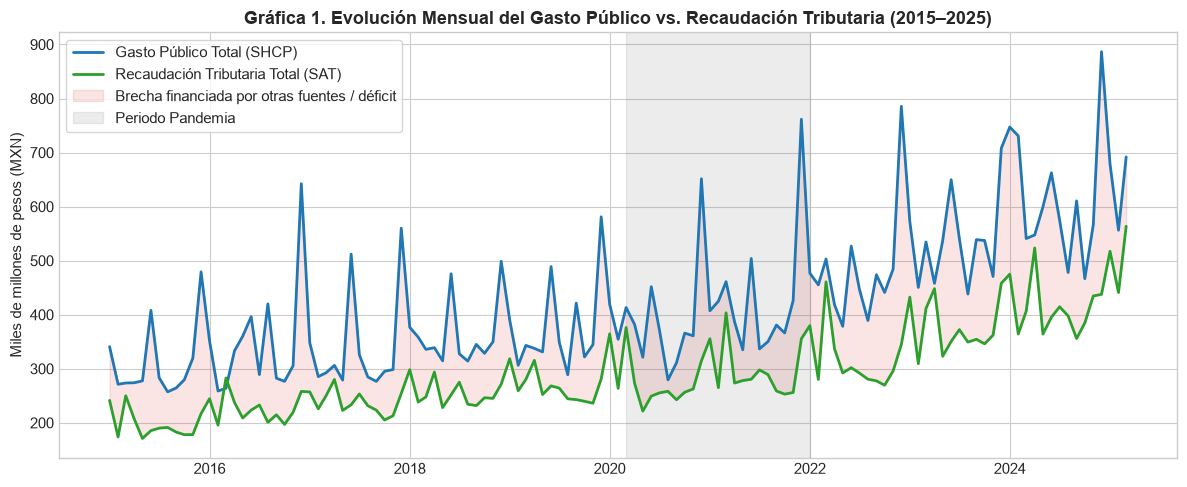

In [44]:
etapa(spark, '7_visualizaciones')

pdf_graf = (
    df_analitico
    .select(
        'fecha', 'shcp_xbc', 'sat_total_tributarios', 'sat_isr', 'sat_iva',
        'igae_total', 'inpc', 'ratio_tributario_gasto',
        'igae_var_anual_pct', 'inflacion_anual_pct',
        'gasto_var_anual_pct', 'sat_var_anual_pct'
    )
    .orderBy('fecha')
    .toPandas()
)
pdf_graf['fecha'] = pd.to_datetime(pdf_graf['fecha'])

# --- GRÁFICA 1: Evolución nominal de Gasto Público vs. Recaudación Tributaria ---
fig, ax = plt.subplots(figsize=(12, 5))
ax.plot(pdf_graf['fecha'], pdf_graf['shcp_xbc'] / 1000, label='Gasto Público Total (SHCP)', color='#1f77b4', linewidth=2)
ax.plot(pdf_graf['fecha'], pdf_graf['sat_total_tributarios'] / 1000, label='Recaudación Tributaria Total (SAT)', color='#2ca02c', linewidth=2)
ax.fill_between(pdf_graf['fecha'], pdf_graf['sat_total_tributarios'] / 1000, pdf_graf['shcp_xbc'] / 1000,
                color='#d62728', alpha=0.12, label='Brecha financiada por otras fuentes / déficit')

ax.axvspan(pd.Timestamp('2020-03-01'), pd.Timestamp('2021-12-31'), color='gray', alpha=0.15, label='Periodo Pandemia')
ax.set_title('Gráfica 1. Evolución Mensual del Gasto Público vs. Recaudación Tributaria (2015–2025)', fontsize=13, fontweight='bold')
ax.set_ylabel('Miles de millones de pesos (MXN)')
ax.legend(loc='upper left', frameon=True)
plt.tight_layout()
plt.show()

> **Interpretación Gráfica 1:** Ambas series muestran una clara tendencia ascendente a lo largo de la década y una fuerte estacionalidad cada diciembre (picos de cierre presupuestal en el gasto) y marzo-abril (declaraciones anuales en el SAT). El área sombreada en rojo muestra que el gasto supera sistemáticamente a los ingresos tributarios, aunque la brecha se amplía notablemente en 2023–2024.

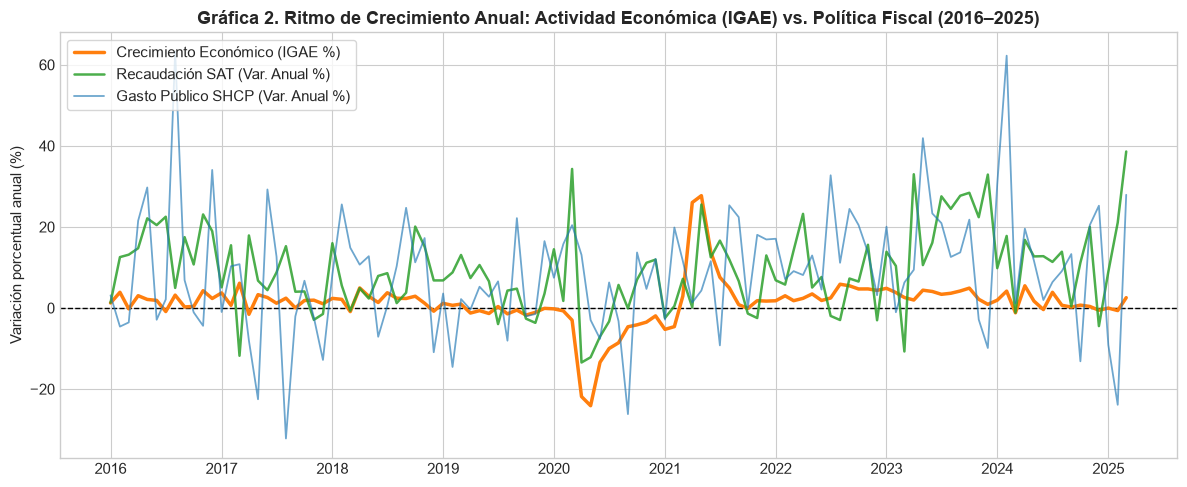

In [45]:
# --- GRÁFICA 2: Tasas de variación anual: IGAE vs. Recaudación y Gasto ---
pdf_tasas_graf = pdf_graf.dropna(subset=['igae_var_anual_pct', 'sat_var_anual_pct', 'gasto_var_anual_pct'])

fig, ax = plt.subplots(figsize=(12, 5))
ax.axhline(0, color='black', linewidth=1, linestyle='--')
ax.plot(pdf_tasas_graf['fecha'], pdf_tasas_graf['igae_var_anual_pct'], label='Crecimiento Económico (IGAE %)', color='#ff7f0e', linewidth=2.5)
ax.plot(pdf_tasas_graf['fecha'], pdf_tasas_graf['sat_var_anual_pct'], label='Recaudación SAT (Var. Anual %)', color='#2ca02c', linewidth=1.8, alpha=0.85)
ax.plot(pdf_tasas_graf['fecha'], pdf_tasas_graf['gasto_var_anual_pct'], label='Gasto Público SHCP (Var. Anual %)', color='#1f77b4', linewidth=1.3, alpha=0.65)

ax.set_title('Gráfica 2. Ritmo de Crecimiento Anual: Actividad Económica (IGAE) vs. Política Fiscal (2016–2025)', fontsize=13, fontweight='bold')
ax.set_ylabel('Variación porcentual anual (%)')
ax.legend(loc='upper left', frameon=True)
plt.tight_layout()
plt.show()

> **Interpretación Gráfica 2:** Al eliminar la tendencia inflacionaria mediante tasas anuales, se observa visualmente el hallazgo del Objetivo 1: la curva verde (recaudación) acompaña de cerca el desplome de 2020 y el rebote de 2021 del IGAE (curva naranja, `r = 0.33`), mientras que el gasto público (curva azul) presenta alta volatilidad mensual sin seguir el ciclo económico.

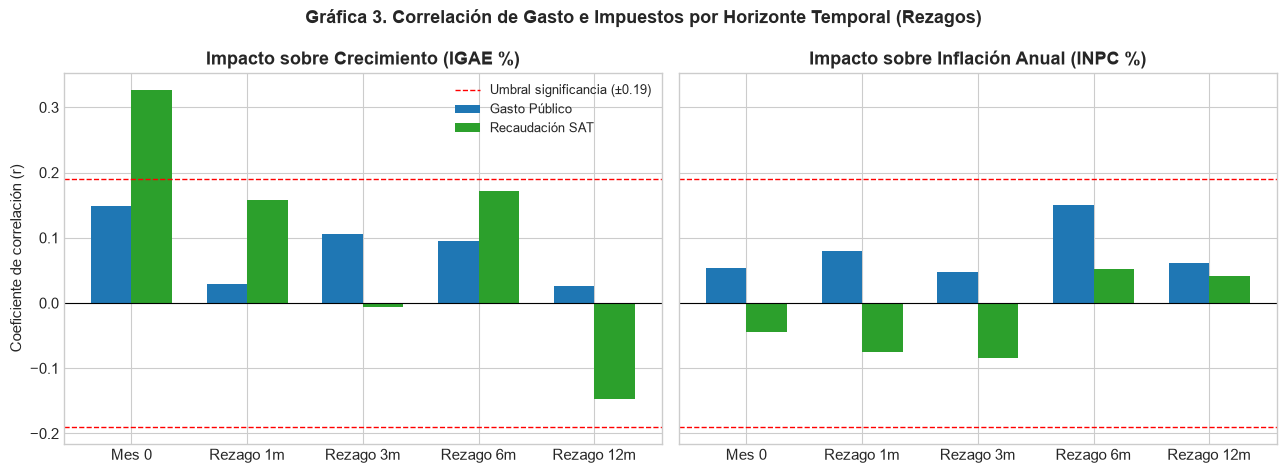

In [46]:
# --- GRÁFICA 3: Correlación cruzada por rezagos (0, 1, 3, 6 y 12 meses) ---
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8), sharey=True)

rezagos_labels = ['Mes 0', 'Rezago 1m', 'Rezago 3m', 'Rezago 6m', 'Rezago 12m']

cols_gasto = [
    'gasto_var_anual_pct',
    'gasto_var_lag1',
    'gasto_var_lag3',
    'gasto_var_lag6',
    'gasto_var_lag12'
]
cols_sat = [
    'sat_var_anual_pct',
    'sat_var_lag1',
    'sat_var_lag3',
    'sat_var_lag6',
    'sat_var_lag12'
]

# Extraer por nombre exacto (si algún rezago no existiera, .reindex pone NaN en lugar de romper el tamaño)
s_igae = sig_igae.set_index('variable')['r']
s_inf = sig_inf.set_index('variable')['r']

r_gasto_igae = s_igae.reindex(cols_gasto).values
r_sat_igae = s_igae.reindex(cols_sat).values
r_gasto_inf = s_inf.reindex(cols_gasto).values
r_sat_inf = s_inf.reindex(cols_sat).values

x = np.arange(len(rezagos_labels))
width = 0.35

# Panel izquierdo: IGAE
axes[0].bar(x - width/2, r_gasto_igae, width, label='Gasto Público', color='#1f77b4')
axes[0].bar(x + width/2, r_sat_igae, width, label='Recaudación SAT', color='#2ca02c')
axes[0].axhline(0.19, color='red', linestyle='--', linewidth=1, label='Umbral significancia (±0.19)')
axes[0].axhline(-0.19, color='red', linestyle='--', linewidth=1)
axes[0].axhline(0, color='black', linewidth=0.8)
axes[0].set_title('Impacto sobre Crecimiento (IGAE %)', fontweight='bold')
axes[0].set_xticks(x)
axes[0].set_xticklabels(rezagos_labels)
axes[0].set_ylabel('Coeficiente de correlación (r)')
axes[0].legend(loc='upper right', fontsize=9)

# Panel derecho: Inflación
axes[1].bar(x - width/2, r_gasto_inf, width, label='Gasto Público', color='#1f77b4')
axes[1].bar(x + width/2, r_sat_inf, width, label='Recaudación SAT', color='#2ca02c')
axes[1].axhline(0.19, color='red', linestyle='--', linewidth=1, label='Umbral significancia (±0.19)')
axes[1].axhline(-0.19, color='red', linestyle='--', linewidth=1)
axes[1].axhline(0, color='black', linewidth=0.8)
axes[1].set_title('Impacto sobre Inflación Anual (INPC %)', fontweight='bold')
axes[1].set_xticks(x)
axes[1].set_xticklabels(rezagos_labels)

plt.suptitle('Gráfica 3. Correlación de Gasto e Impuestos por Horizonte Temporal (Rezagos)', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

> **Interpretación Gráfica 3:** Las líneas punteadas rojas marcan el umbral de significancia estadística (`±0.19` para `p < 0.05`). Únicamente la recaudación en el mes contemporáneo (`Mes 0`) supera dicho umbral frente al crecimiento económico (`r = 0.327`), demostrando que el efecto fiscal sobre el ciclo de corto plazo es inmediato y responde al dinamismo de la economía.

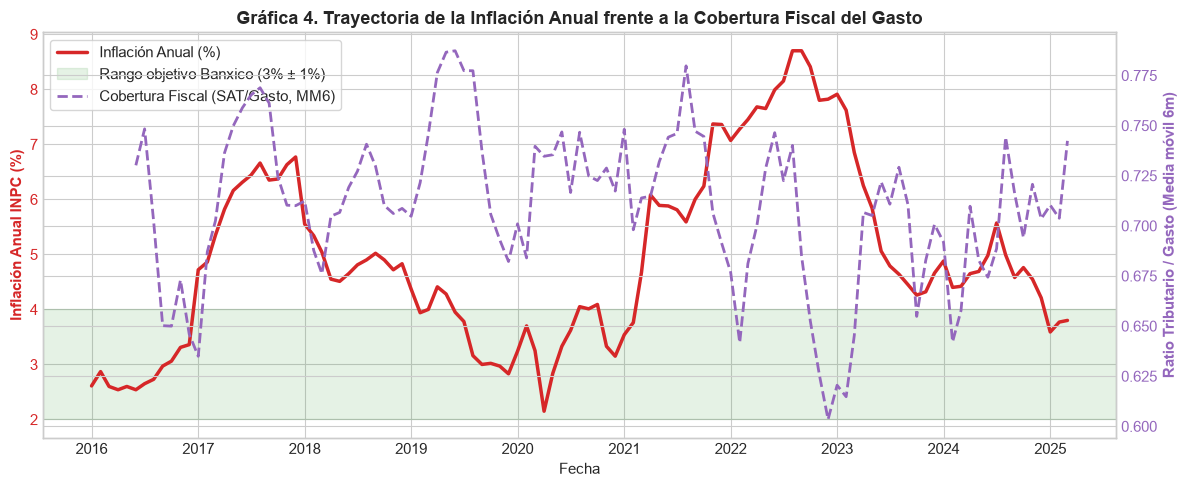

In [47]:
# GRÁFICA 4: Inflación Anual vs. Cobertura Tributaria del Gasto (Ratio SAT/SHCP)
fig, ax1 = plt.subplots(figsize=(12, 5))

color_inf = '#d62728'
ax1.set_xlabel('Fecha')
ax1.set_ylabel('Inflación Anual INPC (%)', color=color_inf, fontweight='bold')
ax1.plot(pdf_tasas_graf['fecha'], pdf_tasas_graf['inflacion_anual_pct'], color=color_inf, linewidth=2.5, label='Inflación Anual (%)')
ax1.tick_params(axis='y', labelcolor=color_inf)
ax1.axhspan(2.0, 4.0, color='green', alpha=0.1, label='Rango objetivo Banxico (3% ± 1%)')

ax2 = ax1.twinx()
color_rat = '#9467bd'
ax2.set_ylabel('Ratio Tributario / Gasto (Media móvil 6m)', color=color_rat, fontweight='bold')
ax2.plot(pdf_tasas_graf['fecha'], pdf_tasas_graf['ratio_tributario_gasto'].rolling(6).mean(),
         color=color_rat, linestyle='--', linewidth=2, label='Cobertura Fiscal (SAT/Gasto, MM6)')
ax2.tick_params(axis='y', labelcolor=color_rat)

plt.title('Gráfica 4. Trayectoria de la Inflación Anual frente a la Cobertura Fiscal del Gasto', fontsize=13, fontweight='bold')

# <-- AQUÍ VA EL PUNTO D: Combinar leyendas de ax1 y ax2 en un solo recuadro
lines1, labels1 = ax1.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()
ax1.legend(lines1 + lines2, labels1 + labels2, loc='upper left', frameon=True)

fig.tight_layout()
plt.show()

> **Interpretación Gráfica 4:** La inflación superó el rango objetivo de Banxico (franja verde) entre 2021 y 2023, alcanzando un máximo de `8.7%`. La cobertura tributaria suavizada a 6 meses (línea morada) osciló de forma estable alrededor de `0.71` (71% del gasto cubierto por impuestos), confirmando visualmente por qué el ratio por sí solo no explica los repuntes inflacionarios.

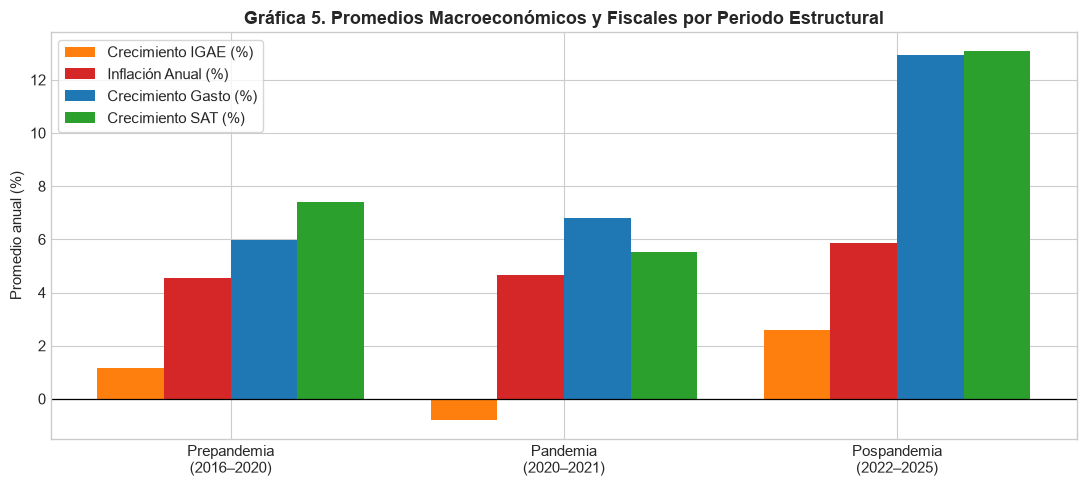

In [48]:
# --- GRÁFICA 5: Comparativo estructural por periodo (Prepandemia, Pandemia y Pospandemia) ---
fig, ax = plt.subplots(figsize=(11, 5))

periodos_labels = ['Prepandemia\n(2016–2020)', 'Pandemia\n(2020–2021)', 'Pospandemia\n(2022–2025)']
x = np.arange(len(periodos_labels))
w_bar = 0.2

ax.bar(x - 1.5*w_bar, pdf_periodos['igae_prom_pct'], w_bar, label='Crecimiento IGAE (%)', color='#ff7f0e')
ax.bar(x - 0.5*w_bar, pdf_periodos['inflacion_prom_pct'], w_bar, label='Inflación Anual (%)', color='#d62728')
ax.bar(x + 0.5*w_bar, pdf_periodos['gasto_var_prom_pct'], w_bar, label='Crecimiento Gasto (%)', color='#1f77b4')
ax.bar(x + 1.5*w_bar, pdf_periodos['sat_var_prom_pct'], w_bar, label='Crecimiento SAT (%)', color='#2ca02c')

ax.axhline(0, color='black', linewidth=0.9)
ax.set_title('Gráfica 5. Promedios Macroeconómicos y Fiscales por Periodo Estructural', fontsize=13, fontweight='bold')
ax.set_ylabel('Promedio anual (%)')
ax.set_xticks(x)
ax.set_xticklabels(periodos_labels)
ax.legend(loc='upper left', frameon=True)
plt.tight_layout()
plt.show()

> **Interpretación Gráfica 5:** El contraste entre etapas muestra un cambio de régimen claro: en la **Pospandemia (2022–2025)** tanto el gasto público (`12.9%`) como la recaudación (`13.1%`) crecieron al doble del ritmo histórico, acompañando una recuperación del IGAE (`2.6%`) pero en un entorno de mayor inflación promedio (`5.9%`).

## 8. Cómo Trabajó Spark Durante el Análisis (Métricas de la Spark UI)

A lo largo del cuaderno, cada bloque de procesamiento etiquetó sus operaciones mediante `etapa(spark, ...)`. A continuación se resumen las métricas de ejecución registradas por `src.monitoring` para verificar el impacto del caché (`df_analitico.cache()`) y la eliminación de *shuffles* innecesarios.

In [49]:
# Incluir todas las etapas etiquetadas en el cuaderno
etapas_registradas = [
    '2_carga', '2_validacion_calidad', '2b_consumo_spark_sql',
    '3_indicadores', '4_objetivo1', '5_objetivo2', '6_periodos', '7_visualizaciones'
]

filas_metricas = []
for et in etapas_registradas:
    m = metricas(spark, nombre=et)
    if isinstance(m, dict):
        filas_metricas.append(m)
    elif isinstance(m, pd.DataFrame) and not m.empty:
        filas_metricas.append(m)

if filas_metricas:
    df_metricas_final = pd.DataFrame(filas_metricas) if isinstance(filas_metricas[0], dict) else pd.concat(filas_metricas, ignore_index=True)
    print('=== RESUMEN DE EJECUCIÓN DE APACHE SPARK POR ETAPA ===')
    print(df_metricas_final.to_string(index=False))

=== RESUMEN DE EJECUCIÓN DE APACHE SPARK POR ETAPA ===
               etapa  jobs  stages  tareas  lectura_MB  escritura_MB  shuffle_KB  tiempo_tareas_s
             2_carga     6       6      36        0.64           0.0        21.1            11.45
2_validacion_calidad     7       7      37        0.64           0.0         4.4             3.99
2b_consumo_spark_sql     5       5      35        1.03           0.0         3.2             3.83
       3_indicadores     3       3      13        0.33           0.0        37.6             1.26
         4_objetivo1    64      64     274        6.93           0.0        73.3            13.64
         5_objetivo2     6       6       6        0.35           0.0         0.0             0.12
          6_periodos     1       1       1        0.06           0.0         0.0             0.09
   7_visualizaciones     1       1       1        0.06           0.0         0.0             0.01


**Lectura de rendimiento en Spark:**
* **Materialización inicial (`2_carga` y `3_indicadores`):** La lectura del esquema Parquet particionado (`2_carga`, 6 jobs / 36 tareas) y el cálculo de las 14 ventanas cronológicas mediante `Exchange SinglePartition` (`3_indicadores`, 3 jobs / 13 tareas, 37.6 KB de shuffle) se ejecutan una sola vez y persisten el resultado en memoria (`df_analitico.cache()`).
* **Concentración de cómputo en `4_objetivo1`:** Esta etapa concentra la mayor carga del cuaderno (**64 jobs y 274 tareas**, 6.93 MB leídos desde memoria) debido a las múltiples matrices de correlación (`VectorAssembler` + `Correlation.corr`) y pruebas de rezagos iterativas sobre gasto total, gasto programable, ISR e IVA.
* **Eficiencia en etapas posteriores (`5_objetivo2`, `6_periodos`, `7_visualizaciones`):** Gracias a `InMemoryTableScan`, las agregaciones por régimen fiscal, los cortes por periodo y la extracción para gráficas operan con **0.0 KB de shuffle** en menos de 0.2 segundos por etapa.

## Arquitectura Aplicada y Evolución del Sistema

* **Flujo de datos de extremo a extremo:**
  `Fuentes oficiales (CSV/XLSX de SHCP, SAT e INEGI)` $\rightarrow$ `Ingesta y limpieza modular en PySpark (Bronze/Silver)` $\rightarrow$ `Almacenamiento analítico en Parquet particionado por año (data/gold/dataset_maestro)` $\rightarrow$ `Capa de consumo (Spark SQL + PySpark ML + Window Functions)` $\rightarrow$ `Reportes estadísticos y visualizaciones ejecutivas`.
* **Almacenamiento y reutilización:** La capa Gold se almacena en formato columnar **Apache Parquet** particionado por `anio`. Esto permite que las consultas SQL y modelos analíticos lean únicamente las columnas y particiones necesarias (*column pruning* y *partition pushdown*) sin reprocesar la ingesta ni los cruces de las fuentes crudas.
* **Implementación actual vs. evolución futura:** Actualmente opera como un **pipeline batch local con arquitectura Medallion** sobre archivos Parquet. En un entorno productivo de mayor escala, evolucionaría hacia un **Lakehouse (Delta Lake / Apache Iceberg)** en almacenamiento en la nube (S3 / ADLS) para habilitar transacciones ACID, control de versiones (*time travel*) y conexión directa con tableros de BI.
* **Incorporación de nuevos datos o correcciones:** Para agregar nuevos meses (abril 2025 en adelante) o actualizar cifras revisadas por SHCP/INEGI, basta con colocar los archivos actualizados en `data/raw/` y ejecutar `python -m src.pipeline` (sobrescritura idempotente por partición de año), actualizando automáticamente la capa de consumo.

## 9. Conclusiones y Limitaciones

### Respuesta a la pregunta de investigación
Entre enero de 2015 y marzo de 2025, la política fiscal en México (gasto de la SHCP y recaudación del SAT) muestra una **relación asimétrica** con el crecimiento económico y la inflación:

1. **Sobre el crecimiento económico (IGAE):**
   * La recaudación tributaria (especialmente el **IVA**) está fuertemente conectada con la actividad económica en el mismo mes (`r = 0.327`, `p = 0.0007`), pero las pruebas de causalidad de Granger demuestran que **el crecimiento del IGAE anticipa a los impuestos** (rezagos de 1 a 6 meses, `p < 0.05`) y no a la inversa.
   * No se encontró evidencia estadísticamente significativa de que el gasto público (ni total ni programable) impulse el crecimiento mensual del IGAE en horizontes de 0 a 12 meses.

2. **Sobre la estabilidad de precios (INPC):**
   * En el modelo multivariado con errores robustos (Newey-West HAC), **un mayor ritmo de recaudación tributaria se asocia con menor inflación** (`coef = -0.0303`, `p = 0.016`; `-0.0454` controlando por periodos), actuando como un estabilizador automático que retira liquidez de la economía.
   * El gasto público no presiona los precios de forma inmediata, pero las pruebas de Granger revelan que **el crecimiento del gasto anticipa presiones inflacionarias con un rezago de 5 a 6 meses** (`p = 0.009` a `0.014`).
   * La proporción del gasto cubierta con impuestos (`ratio_tributario_gasto`, promedio `70.7%`) no mostró un efecto directo significativo sobre la inflación.

3. **Dinámica por periodos:**
   * Los vínculos estadísticos más fuertes emergieron a partir de **2020**: en pandemia la recaudación reflejó de inmediato la contracción y rebote económico (`r = 0.57`), mientras que en la pospandemia el dinamismo recaudatorio ayudó a moderar presiones de precios (`r = -0.43`).

### Limitaciones del estudio
* **Variables omitidas de política monetaria y choques externos:** El modelo fiscal explica hasta el **40.9%** de la varianza de la inflación (incluyendo efectos de periodo); el resto responde a factores fuera del alcance de este dataset, como la tasa de interés de Banxico, el tipo de cambio y choques globales de oferta.
* **Frecuencia y tamaño de muestra:** Al trabajar con series mensuales agregadas (`N = 123` meses totales, `105` útiles tras rezagos), el análisis captura dinámicas de corto y mediano plazo, pero no efectos estructurales de inversión pública de maduración multianual.
* **Asociación vs. causalidad:** Tanto las correlaciones como las pruebas de Granger miden precedencia temporal y asociación estadística, no causalidad estructural aislada.

In [50]:
# Liberar caché y cerrar la sesión de Spark correctamente
df_analitico.unpersist()
spark.stop()
print('Caché liberada y sesión de Spark finalizada correctamente.')

Caché liberada y sesión de Spark finalizada correctamente.
